<a href="https://colab.research.google.com/github/NSnightKING/IDS-ML/blob/main/FYP.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
!pip install tensorflow scikit-learn imbalanced-learn pandas numpy matplotlib seaborn joblib tqdm catboost xgboost -q

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os
import glob
import gc
import warnings
warnings.filterwarnings('ignore')

from sklearn.preprocessing import LabelEncoder, MinMaxScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, accuracy_score, confusion_matrix
from sklearn.ensemble import RandomForestClassifier, VotingClassifier
from imblearn.over_sampling import SMOTE
import tensorflow as tf
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import ReduceLROnPlateau, ModelCheckpoint
from tensorflow.keras.models import Model
from tensorflow.keras.layers import Input, Conv1D, MaxPooling1D, Flatten, Dense, Dropout, Bidirectional, LSTM, BatchNormalization, GlobalAveragePooling1D
from tensorflow.keras.callbacks import EarlyStopping
import joblib
from tqdm import tqdm
from catboost import CatBoostClassifier
from xgboost import XGBClassifier

np.random.seed(42)
tf.random.set_seed(42)




   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 97.1/97.1 MB 10.1 MB/s eta 0:00:00


# **Install Packages**

# **Import**

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


# **Mount Drive + Paths**

In [ ]:
DATA_FOLDER = '/content/drive/MyDrive/Final-DATA-SET'
OUTPUT_FOLDER = '/content/drive/MyDrive/IDS_Model_Final_2/'
os.makedirs(OUTPUT_FOLDER + 'models/', exist_ok=True)
os.makedirs(OUTPUT_FOLDER + 'figures/', exist_ok=True)

print("✅ Cell 1: Project Setup Completed")


✅ Cell 1: Project Setup Completed


# **Dataset Discovery**

In [ ]:
print("Cell 2: Dataset Discovery...")

csv_files = sorted(glob.glob(os.path.join(DATA_FOLDER, "*.csv")))
print(f"Total CSV files found: {len(csv_files)}")
for f in csv_files:
    print(" -", os.path.basename(f))

Cell 2: Dataset Discovery...
Total CSV files found: 10
 - Friday-02-03-2018_TrafficForML_CICFlowMeter.csv
 - Friday-16-02-2018_TrafficForML_CICFlowMeter.csv
 - Friday-23-02-2018_TrafficForML_CICFlowMeter.csv
 - Thuesday-20-02-2018_TrafficForML_CICFlowMeter.csv
 - Thursday-01-03-2018_TrafficForML_CICFlowMeter.csv
 - Thursday-15-02-2018_TrafficForML_CICFlowMeter.csv
 - Thursday-22-02-2018_TrafficForML_CICFlowMeter.csv
 - Wednesday-14-02-2018_TrafficForML_CICFlowMeter.csv
 - Wednesday-21-02-2018_TrafficForML_CICFlowMeter.csv
 - Wednesday-28-02-2018_TrafficForML_CICFlowMeter.csv


# **Load Dataset**

In [ ]:
print("Cell 3: Data Loading (Low Resource)...")

all_chunks = []
class_counts = {}

CHUNK_SIZE = 30000
MAX_PER_CLASS = 25000
TARGET_TOTAL = 400000

for file_idx, file_path in enumerate(csv_files, 1):
    filename = os.path.basename(file_path)
    print(f"[{file_idx}/{len(csv_files)}] Loading: {filename}")

    for chunk in tqdm(pd.read_csv(file_path, chunksize=CHUNK_SIZE, low_memory=True, on_bad_lines='skip')):
        chunk.columns = chunk.columns.str.strip().str.lower().str.replace(' ', '_').str.replace('.', '').str.replace('__', '_')
        chunk.replace([np.inf, -np.inf], np.nan, inplace=True)
        chunk.fillna(0, inplace=True)
        chunk = chunk.dropna()

        if 'label' not in chunk.columns:
            continue

        sampled = chunk.groupby('label', group_keys=False).apply(
            lambda g: g.sample(n=min(len(g), max(0, MAX_PER_CLASS - class_counts.get(g.name, 0))), random_state=42)
            if class_counts.get(g.name, 0) < MAX_PER_CLASS else pd.DataFrame()
        )

        if not sampled.empty:
            all_chunks.append(sampled)
            for lbl, cnt in sampled['label'].value_counts().items():
                class_counts[lbl] = class_counts.get(lbl, 0) + cnt

        if sum(class_counts.values()) >= TARGET_TOTAL:
            break

    gc.collect()
    if sum(class_counts.values()) >= TARGET_TOTAL:
        break

df = pd.concat(all_chunks, ignore_index=True)
del all_chunks
gc.collect()

print(f"✅ Dataset Loaded: {len(df):,} samples")

Cell 3: Data Loading (Low Resource)...
[1/10] Loading: Friday-02-03-2018_TrafficForML_CICFlowMeter.csv


35it [00:32,  1.06it/s]


[2/10] Loading: Friday-16-02-2018_TrafficForML_CICFlowMeter.csv


35it [00:12,  2.72it/s]


[3/10] Loading: Friday-23-02-2018_TrafficForML_CICFlowMeter.csv


...

[9/10] Loading: Wednesday-21-02-2018_TrafficForML_CICFlowMeter.csv


35it [00:10,  3.49it/s]


[10/10] Loading: Wednesday-28-02-2018_TrafficForML_CICFlowMeter.csv


21it [00:35,  1.71s/it]


✅ Dataset Loaded: 263,707 samples


# **Preview**

In [ ]:
print("Cell 4: Data Preview")
print("Shape:", df.shape)
print(df.head())
print("\nColumns:", df.columns.tolist())

Cell 4: Data Preview
Shape: (263707, 84)
  dst_port protocol            timestamp flow_duration tot_fwd_pkts  \
0     3389        6  02/03/2018 12:12:40     119924706          663   
1      443        6  02/03/2018 09:16:31      10410130            8   
2     3389        6  02/03/2018 11:08:48     119986455          108   
3      443        6  02/03/2018 08:51:25          2206            3   
4     3389        6  02/03/2018 11:00:47     119175193          113   

  tot_bwd_pkts totlen_fwd_pkts totlen_bwd_pkts fwd_pkt_len_max  \
0          434           90630           31386            1460   
1            8             822            4141             503   
2          106              51            5406              51   
3            0              53               0              53   
4          111              51            5661              51   

  fwd_pkt_len_min  ... active_min  idle_mean idle_std   idle_max   idle_min  \
0               0  ...        0.0        0.0      0.0   

# **Data Quality Audit**

In [ ]:
print("Cell 5: Data Quality Audit")
print("Missing Values:", df.isnull().sum().sum())
print("Duplicate Rows:", df.duplicated().sum())
print("Memory Usage (MB):", round(df.memory_usage(deep=True).sum() / 1024**2, 2))

Cell 5: Data Quality Audit
Missing Values: 954828
Duplicate Rows: 47722
Memory Usage (MB): 741.6


# **Label Analysis**

In [ ]:
print("Cell 6: Label Analysis")
print("Unique Labels:", df['label'].unique())
print("\nClass Distribution:\n", df['label'].value_counts())

Cell 6: Label Analysis
Unique Labels: ['Benign' 'Bot' 'DoS attacks-SlowHTTPTest' 'DoS attacks-Hulk' 'Label'
 'Brute Force -Web' 'Brute Force -XSS' 'SQL Injection'
 'DDoS attacks-LOIC-HTTP' 'Infilteration' 'DoS attacks-GoldenEye'
 'DoS attacks-Slowloris' 'FTP-BruteForce' 'SSH-Bruteforce'
 'DDOS attack-HOIC' 'DDOS attack-LOIC-UDP']

Class Distribution:
 label
Benign                      25000
Bot                         25000
DoS attacks-SlowHTTPTest    25000
DoS attacks-Hulk            25000
FTP-BruteForce              25000
DoS attacks-GoldenEye       25000
Infilteration               25000
DDoS attacks-LOIC-HTTP      25000
DDOS attack-HOIC            25000
SSH-Bruteforce              25000
DoS attacks-Slowloris       10990
DDOS attack-LOIC-UDP         1730
Brute Force -Web              611
Brute Force -XSS              230
SQL Injection                  87
Label                          59
Name: count, dtype: int64


# **Pre-training Visualizations**

Cell 7: Pre-training Visualizations


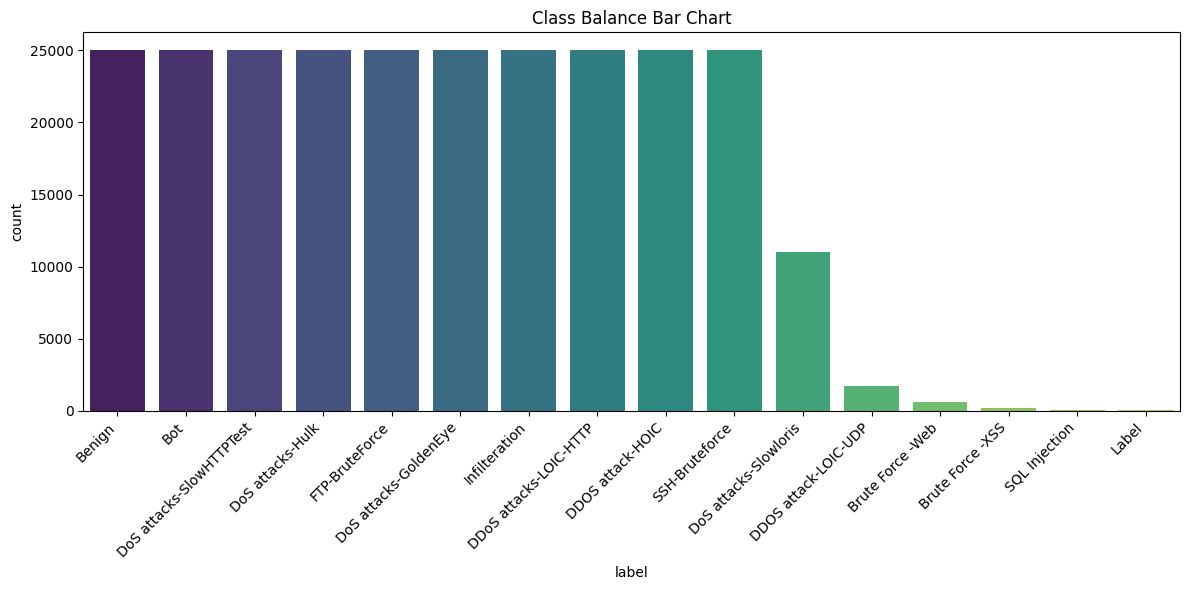

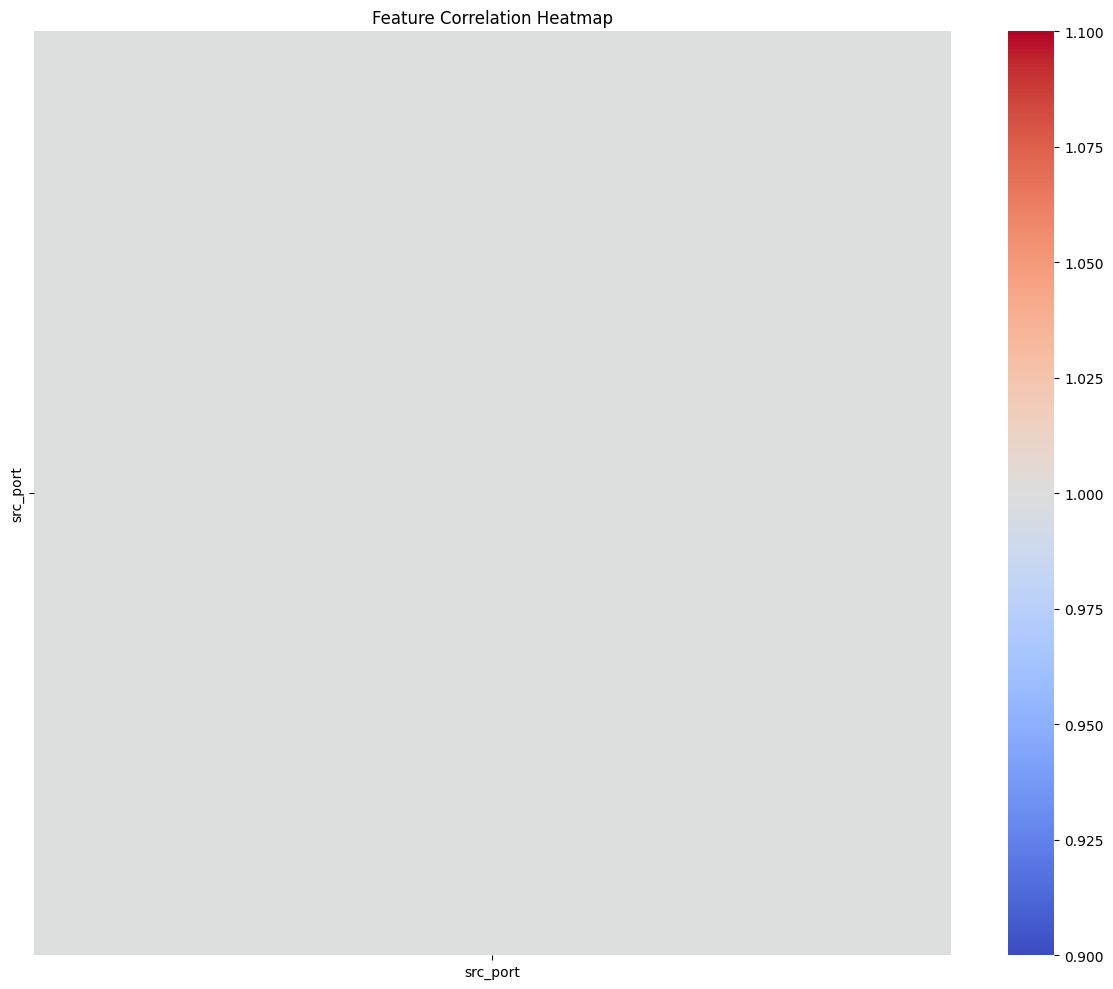

In [ ]:
print("Cell 7: Pre-training Visualizations")

plt.figure(figsize=(12, 6))
sns.countplot(x='label', data=df, order=df['label'].value_counts().index, palette='viridis')
plt.title('Class Balance Bar Chart')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.savefig(OUTPUT_FOLDER + 'figures/class_balance_bar.png', dpi=300)
plt.show()

plt.figure(figsize=(12, 10))
numeric_df = df.select_dtypes(include=[np.number])
sns.heatmap(numeric_df.corr(), cmap='coolwarm', annot=False)
plt.title('Feature Correlation Heatmap')
plt.tight_layout()
plt.savefig(OUTPUT_FOLDER + 'figures/correlation_heatmap.png', dpi=300)
plt.show()

# **Box Plots for Outliers**

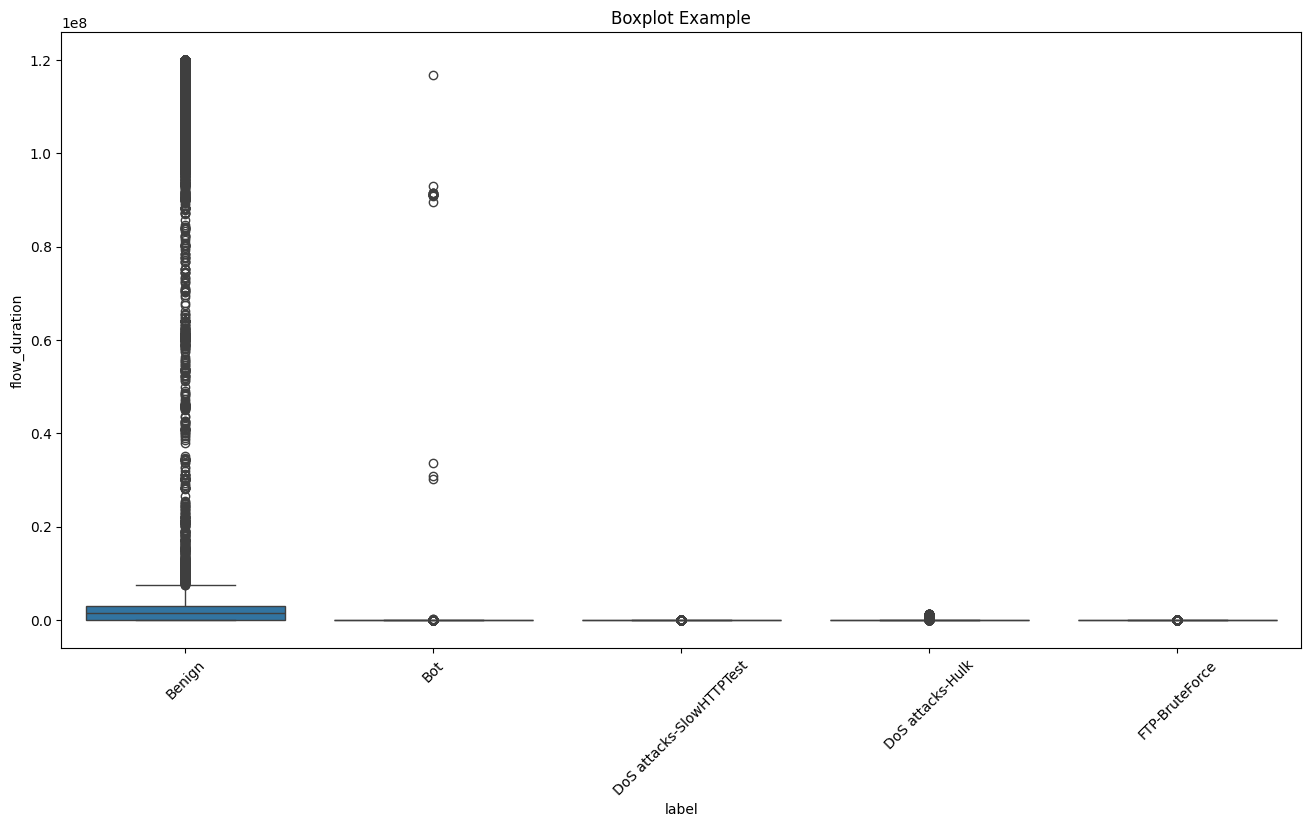

In [ ]:
plt.figure(figsize=(16, 8))
sns.boxplot(x='label', y='flow_duration', data=df[df['label'].isin(df['label'].value_counts().head(5).index)])
plt.title('Boxplot Example')
plt.xticks(rotation=45)
plt.savefig(OUTPUT_FOLDER + 'figures/boxplot.png', dpi=300)
plt.show()

# **Data Cleaning**

In [ ]:
print("Cell 8: Data Cleaning...")

drop_cols = ['flow_id', 'src_ip', 'dst_ip', 'src_port', 'dst_port', 'timestamp', 'protocol']
df.drop(columns=[c for c in drop_cols if c in df.columns], inplace=True, errors='ignore')

df.replace([np.inf, -np.inf], np.nan, inplace=True)
df.fillna(0, inplace=True)
df = df.drop_duplicates()

print(f"✅ After cleaning: {len(df):,} samples")

Cell 8: Data Cleaning...
✅ After cleaning: 174,550 samples


# **Feature Engineering**

In [ ]:
print("Cell 9: Feature Engineering...")

X = df.drop('label', axis=1)
for col in X.columns:
    X[col] = pd.to_numeric(X[col], errors='coerce')

X = X.select_dtypes(include=[np.number])
X = X.loc[:, X.var() > 1e-8]

print(f"✅ Final Features: {X.shape[1]}")

Cell 9: Feature Engineering...
✅ Final Features: 68


# **Label Encoding**

In [ ]:
print("Cell 10: Label Encoding...")

le = LabelEncoder()
y = le.fit_transform(df['label'])
print("Encoded Classes:", list(le.classes_))

Cell 10: Label Encoding...
Encoded Classes: ['Benign', 'Bot', 'Brute Force -Web', 'Brute Force -XSS', 'DDOS attack-HOIC', 'DDOS attack-LOIC-UDP', 'DDoS attacks-LOIC-HTTP', 'DoS attacks-GoldenEye', 'DoS attacks-Hulk', 'DoS attacks-SlowHTTPTest', 'DoS attacks-Slowloris', 'FTP-BruteForce', 'Infilteration', 'Label', 'SQL Injection', 'SSH-Bruteforce']


## **Feature Correlation Heatmap (Post-Feature Engineering)**

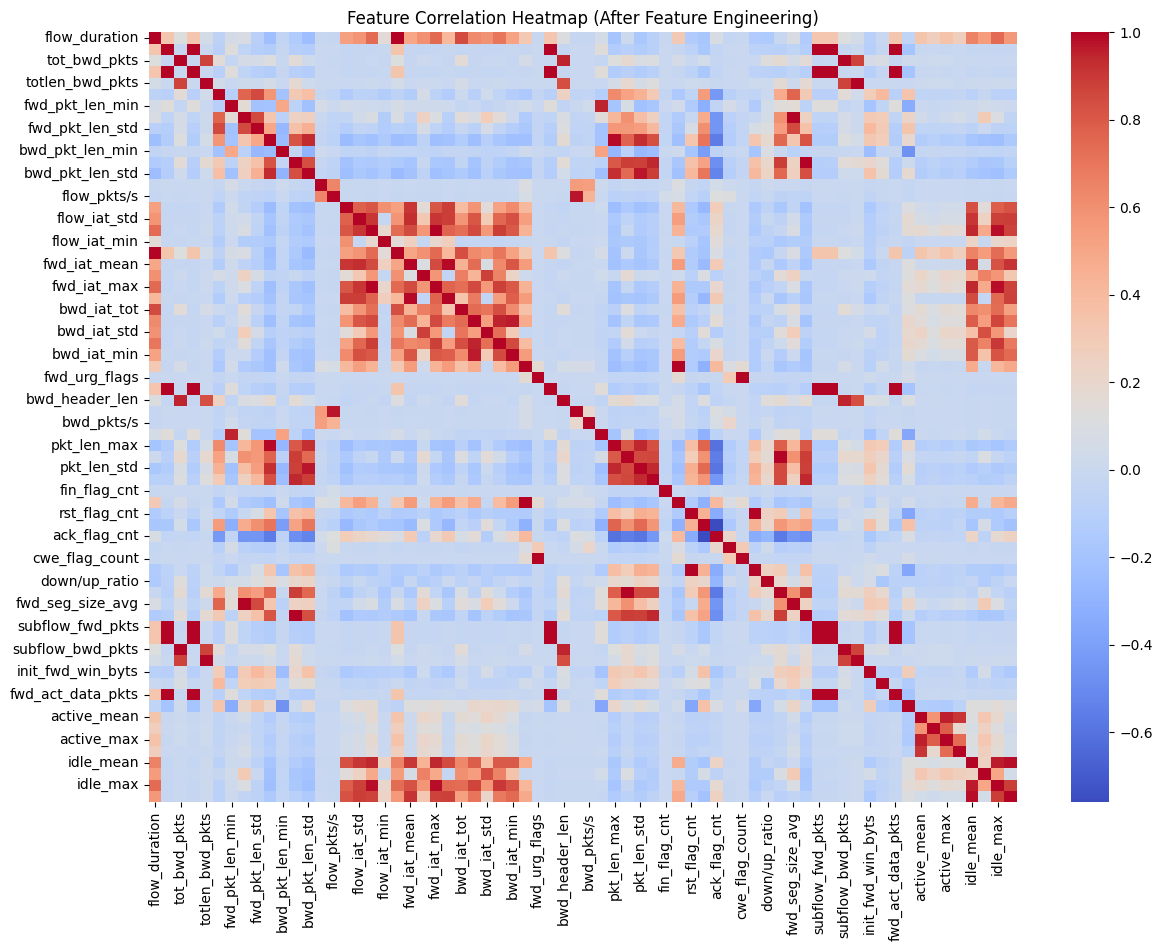

In [ ]:
if X.shape[1] > 1:
    plt.figure(figsize=(14, 10))
    sns.heatmap(X.corr(), cmap='coolwarm', annot=False)
    plt.title('Feature Correlation Heatmap (After Feature Engineering)')
    plt.savefig(OUTPUT_FOLDER + 'figures/correlation_heatmap_post_fe.png', dpi=300)
    plt.show()
else:
    print("Not enough numerical features in X to generate a correlation heatmap.")

# **Train/Test Split**

In [ ]:
print("Cell 11: Train-Test Split...")

# Get class counts for `y`
class_counts_y = pd.Series(y).value_counts()

# Identify classes with only one member (using the original integer labels from 'y')
single_sample_classes_int = class_counts_y[class_counts_y == 1].index

# Create a temporary LabelEncoder instance to safely get the original class names
# without relying on the potentially modified global `le`'s `classes_` attribute.
temp_le_for_names = LabelEncoder()
temp_le_for_names.fit(df['label']) # Fit it to the original df['label'] to ensure it has the complete, correct mapping

# Get the string names of these single-sample classes for printing
single_sample_class_names = temp_le_for_names.inverse_transform(single_sample_classes_int)

# Create a boolean mask to filter out samples belonging to single_sample_classes
mask = ~np.isin(y, single_sample_classes_int)

# Apply the mask to X and y
X_filtered = X[mask]
y_filtered = y[mask]

if len(single_sample_classes_int) > 0:
    print(f"Removed {len(single_sample_classes_int)} classes with only one sample: {single_sample_class_names}")
    print(f"New dataset size after removing single-sample classes: {X_filtered.shape[0]} samples")
else:
    print("No classes with a single sample found.")

# Re-encode y_filtered to ensure contiguous labels for the remaining classes (0 to N-1).
# y_filtered still contains the original integer labels (e.g., [0, 1, ..., 12, 14, 15])
# We get the unique original integer labels that remain after filtering.
unique_remaining_original_labels = np.unique(y_filtered)

# Create a mapping from old integer labels to new contiguous integer labels
label_mapping = {old_label: new_label for new_label, old_label in enumerate(unique_remaining_original_labels)}

# Apply the mapping to get the final contiguous labels for y
y_final = np.array([label_mapping[label] for label in y_filtered])

# Update the original LabelEncoder's classes_ attribute to reflect the new,
# contiguous mapping using the *string names* of the remaining classes.
# This ensures that le.inverse_transform will work correctly with the new labels (0 to N-1).
le.classes_ = temp_le_for_names.inverse_transform(unique_remaining_original_labels)

print(f"Final number of classes after re-encoding: {len(np.unique(y_final))}")
print(f"Re-encoded classes (string names): {list(le.classes_)}")

X_train, X_test, y_train, y_test = train_test_split(
    X_filtered, y_final, test_size=0.2, random_state=42, stratify=y_final
)
print(f"Train: {X_train.shape[0]} | Test: {X_test.shape[0]}")

Cell 11: Train-Test Split...
Removed 1 classes with only one sample: ['Label']
New dataset size after removing single-sample classes: 174549 samples
Final number of classes after re-encoding: 15
Re-encoded classes (string names): ['Benign', 'Bot', 'Brute Force -Web', 'Brute Force -XSS', 'DDOS attack-HOIC', 'DDOS attack-LOIC-UDP', 'DDoS attacks-LOIC-HTTP', 'DoS attacks-GoldenEye', 'DoS attacks-Hulk', 'DoS attacks-SlowHTTPTest', 'DoS attacks-Slowloris', 'FTP-BruteForce', 'Infilteration', 'SQL Injection', 'SSH-Bruteforce']
Train: 139639 | Test: 34910


# **Scaling**

In [ ]:
print("Cell 12: Scaling...")

scaler = MinMaxScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)
print("✅ Scaling Completed")

Cell 12: Scaling...
✅ Scaling Completed


# **Imbalance Handling**

In [ ]:
print("Cell 13: SMOTE...")

smote = SMOTE(random_state=42, k_neighbors=5)
X_res, y_res = smote.fit_resample(X_train_scaled, y_train)
print("After SMOTE:", np.bincount(y_res))

Cell 13: SMOTE...
After SMOTE: [20000 20000 20000 20000 20000 20000 20000 20000 20000 20000 20000 20000
 20000 20000 20000]


# **Feature Selection**

In [ ]:
print("Cell 14: Feature Selection...")

rf = RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1)
rf.fit(X_res, y_res)

feature_importance = pd.DataFrame({
    'feature': X.columns,
    'importance': rf.feature_importances_
}).sort_values('importance', ascending=False)

print(feature_importance.head(10))

Cell 14: Feature Selection...
              feature  importance
56  init_fwd_win_byts    0.067766
59   fwd_seg_size_min    0.053097
0       flow_duration    0.047829
34         bwd_pkts/s    0.042809
17       flow_iat_max    0.041949
33         fwd_pkts/s    0.037207
14        flow_pkts/s    0.036630
31     fwd_header_len    0.034888
15      flow_iat_mean    0.030956
1        tot_fwd_pkts    0.030446


# **Dimensionality Reduction (PCA)**

Cell 15: PCA...


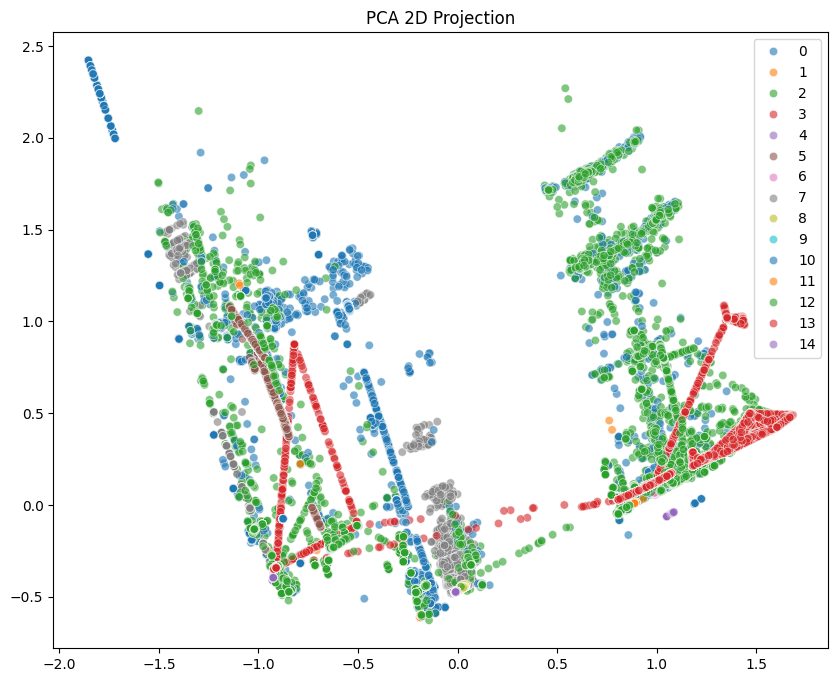

In [ ]:
print("Cell 15: PCA...")

from sklearn.decomposition import PCA
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_res)

plt.figure(figsize=(10, 8))
sns.scatterplot(x=X_pca[:,0], y=X_pca[:,1], hue=y_res, palette='tab10', alpha=0.6)
plt.title('PCA 2D Projection')
plt.savefig(OUTPUT_FOLDER + 'figures/pca_2d.png', dpi=300)
plt.show()

# **Baseline Model Training**

In [ ]:
print("Cell 16: Baseline Models...")

models = {
    'RandomForest': RandomForestClassifier(n_estimators=500, max_depth=20, random_state=42, n_jobs=-1),
    'XGBoost': XGBClassifier(n_estimators=500, learning_rate=0.05, max_depth=8, random_state=42, eval_metric='mlogloss'),
    'CatBoost': CatBoostClassifier(iterations=500, depth=8, learning_rate=0.05, verbose=False, random_state=42)
}

results = {}
for name, model in models.items():
    print(f"Training {name}...")
    model.fit(X_res, y_res)
    y_pred = model.predict(X_test_scaled)
    results[name] = accuracy_score(y_test, y_pred)
    print(f"{name} Accuracy: {results[name]:.4f}")

Cell 16: Baseline Models...
Training RandomForest...
RandomForest Accuracy: 0.9360
Training XGBoost...
XGBoost Accuracy: 0.9389
Training CatBoost...
CatBoost Accuracy: 0.9337


# **Deep Learning Training**

In [ ]:
print("Cell 17: Deep Learning Training...")

# FIX: Use SMOTE-resampled data for deep learning
X_res_dl = X_res.reshape(-1, X_res.shape[1], 1)
X_test_dl = X_test_scaled.reshape(-1, X_test_scaled.shape[1], 1)
print(f"DL Training Shape: {X_res_dl.shape}, Classes: {len(np.unique(y_res))}")

# Enhanced callbacks
early_stop = EarlyStopping(monitor='val_accuracy', patience=12, restore_best_weights=True, verbose=1)
lr_reducer = ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=4, min_lr=1e-7, verbose=1)
checkpoint_cnn = ModelCheckpoint(OUTPUT_FOLDER + 'models/best_cnn_model.keras', monitor='val_accuracy', save_best_only=True, verbose=1)
checkpoint_lstm = ModelCheckpoint(OUTPUT_FOLDER + 'models/best_lstm_model.keras', monitor='val_accuracy', save_best_only=True, verbose=1)


Cell 17: Deep Learning Training...
DL Training Shape: (300000, 68, 1), Classes: 15


# **CNN Model**

In [ ]:
print("Training CNN...")
inputs = Input(shape=(X_res_dl.shape[1], 1))

# Block 1
x = Conv1D(64, 7, padding='same', activation='relu')(inputs)
x = BatchNormalization()(x)
x = MaxPooling1D(2)(x)

# Block 2
x = Conv1D(128, 5, padding='same', activation='relu')(x)
x = BatchNormalization()(x)
x = MaxPooling1D(2)(x)

# Block 3
x = Conv1D(256, 3, padding='same', activation='relu')(x)
x = BatchNormalization()(x)
x = MaxPooling1D(2)(x)

# GlobalAveragePooling reduces parameters vs Flatten (less overfitting)
x = GlobalAveragePooling1D()(x)

# Deeper dense head
x = Dense(256, activation='relu')(x)
x = BatchNormalization()(x)
x = Dropout(0.5)(x)

x = Dense(128, activation='relu')(x)
x = Dropout(0.3)(x)

outputs = Dense(len(le.classes_), activation='softmax')(x)
cnn_model = Model(inputs, outputs)
cnn_model.compile(optimizer=Adam(learning_rate=0.001), loss='sparse_categorical_crossentropy', metrics=['accuracy'])

cnn_history = cnn_model.fit(
    X_res_dl, y_res,
    epochs=50,
    batch_size=64,
    validation_split=0.2,
    callbacks=[early_stop, lr_reducer, checkpoint_cnn],
    verbose=1
)


Training CNN...
Epoch 1/50
3749/3750 ━━━━━━━━━━━━━━━━━━━━ 0s 57ms/step - accuracy: 0.8745 - loss: 0.3604
Epoch 1: val_accuracy improved from None to 0.30375, saving model to /content/drive/MyDrive/IDS_Model_Final_2/models/best_cnn_model.keras

Epoch 1: finished saving model to /content/drive/MyDrive/IDS_Model_Final_2/models/best_cnn_model.keras
3750/3750 ━━━━━━━━━━━━━━━━━━━━ 236s 62ms/step - accuracy: 0.9041 - loss: 0.2391 - val_accuracy: 0.3038 - val_loss: 6.3436 - learning_rate: 0.0010
Epoch 2/50
3749/3750 ━━━━━━━━━━━━━━━━━━━━ 0s 57ms/step - accuracy: 0.9193 - loss: 0.1803
Epoch 2: val_accuracy improved from 0.30375 to 0.31590, saving model to /content/drive/MyDrive/IDS_Model_Final_2/models/best_cnn_model.keras

Epoch 2: finished saving model to /content/drive/MyDrive/IDS_Model_Final_2/models/best_cnn_model.keras
3750/3750 ━━━━━━━━━━━━━━━━━━━━ 236s 63ms/step - accuracy: 0.9204 - loss: 0.1768 - val_accuracy: 0.3159 - val_loss: 4.0021 - learning_rate: 0.0010
Epoch 3/50
3750/3750 ━━━━━━

# LSTM Model

In [ ]:
"""# **Balanced LSTM Model**"""
print("Training Balanced LSTM...")
inputs = Input(shape=(X_res_dl.shape[1], 1))

x = Bidirectional(LSTM(96, return_sequences=False))(inputs)
x = BatchNormalization()(x)
x = Dropout(0.4)(x)

x = Dense(192, activation='relu')(x)
x = BatchNormalization()(x)
x = Dropout(0.4)(x)

x = Dense(96, activation='relu')(x)
x = Dropout(0.25)(x)

outputs = Dense(len(le.classes_), activation='softmax')(x)
lstm_model = Model(inputs, outputs)
lstm_model.compile(optimizer=Adam(learning_rate=0.001), loss='sparse_categorical_crossentropy', metrics=['accuracy'])

lstm_history = lstm_model.fit(
    X_res_dl, y_res,
    epochs=50,
    batch_size=128,      # Changed from 256 to 128
    validation_split=0.2,
    callbacks=[early_stop, lr_reducer, checkpoint_lstm],
    verbose=1
)

Training Balanced LSTM...
Epoch 1/50
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 0s 208ms/step - accuracy: 0.7617 - loss: 0.7249
Epoch 1: val_accuracy did not improve from 0.30682
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 463s 230ms/step - accuracy: 0.8503 - loss: 0.4306 - val_accuracy: 0.2948 - val_loss: 5.3323 - learning_rate: 0.0010
Epoch 2/50
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 0s 209ms/step - accuracy: 0.9021 - loss: 0.2530
Epoch 2: val_accuracy did not improve from 0.30682
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 432s 230ms/step - accuracy: 0.9038 - loss: 0.2446 - val_accuracy: 0.2458 - val_loss: 5.5477 - learning_rate: 0.0010
Epoch 3/50
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 0s 207ms/step - accuracy: 0.9059 - loss: 0.2348
Epoch 3: val_accuracy did not improve from 0.30682
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 426s 227ms/step - accuracy: 0.9073 - loss: 0.2294 - val_accuracy: 0.2914 - val_loss: 5.1058 - learning_rate: 0.0010
Epoch 4/50
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 0s 207ms/step - accuracy: 0.9099 - loss: 0.2221
Epoch 4: ReduceLROnP

In [ ]:
# Evaluate DL models on test set
print("\nEvaluating Deep Learning Models...")
cnn_test_loss, cnn_test_acc = cnn_model.evaluate(X_test_dl, y_test, verbose=0)
results['CNN'] = cnn_test_acc
print(f"CNN Test Accuracy: {cnn_test_acc:.4f}")

lstm_test_loss, lstm_test_acc = lstm_model.evaluate(X_test_dl, y_test, verbose=0)
results['LSTM'] = lstm_test_acc
print(f"LSTM Test Accuracy: {lstm_test_acc:.4f}")

print("✅ Deep Learning Completed")


Evaluating Deep Learning Models...
CNN Test Accuracy: 0.9270
LSTM Test Accuracy: 0.8875
✅ Deep Learning Completed


# **Ensemble Model**

In [ ]:
print("Cell 18: Ensemble Model...")

# Traditional ML soft-voting ensemble
voting = VotingClassifier(
    estimators=[(name, model) for name, model in models.items()],
    voting='soft'
)
voting.fit(X_res, y_res)

# Get probabilities from all 5 models
ml_probs = voting.predict_proba(X_test_scaled)
cnn_probs = cnn_model.predict(X_test_dl)
lstm_probs = lstm_model.predict(X_test_dl)

# Hybrid ensemble: average all 5 model probabilities
hybrid_probs = (ml_probs + cnn_probs + lstm_probs) / 3
hybrid_pred = np.argmax(hybrid_probs, axis=1)
hybrid_acc = accuracy_score(y_test, hybrid_pred)
results['Hybrid_Ensemble'] = hybrid_acc
print(f"Hybrid Ensemble (RF+XGB+CatBoost+CNN+LSTM) Accuracy: {hybrid_acc:.4f}")

# Traditional ensemble for comparison
trad_pred = voting.predict(X_test_scaled)
trad_acc = accuracy_score(y_test, trad_pred)
print(f"Traditional ML Ensemble Accuracy: {trad_acc:.4f}")
print("✅ Ensembles Trained")

Cell 18: Ensemble Model...
1091/1091 ━━━━━━━━━━━━━━━━━━━━ 11s 10ms/step
1091/1091 ━━━━━━━━━━━━━━━━━━━━ 26s 23ms/step
Hybrid Ensemble (RF+XGB+CatBoost+CNN+LSTM) Accuracy: 0.9312
Traditional ML Ensemble Accuracy: 0.9388
✅ Ensembles Trained


# **Model Evaluation**

In [ ]:
print("Cell 19: Model Evaluation...")

# Use hybrid ensemble as final prediction
y_pred = hybrid_pred
print("Final Hybrid Ensemble Accuracy:", accuracy_score(y_test, y_pred))
print(classification_report(y_test, y_pred, target_names=le.classes_))

Cell 19: Model Evaluation...
Final Hybrid Ensemble Accuracy: 0.9312231452305929
                          precision    recall  f1-score   support

                  Benign       0.80      0.68      0.74      4773
                     Bot       1.00      0.99      0.99      2618
        Brute Force -Web       0.57      1.00      0.73       111
        Brute Force -XSS       0.64      0.98      0.77        45
        DDOS attack-HOIC       1.00      1.00      1.00      4055
    DDOS attack-LOIC-UDP       1.00      1.00      1.00       346
  DDoS attacks-LOIC-HTTP       1.00      1.00      1.00      5000
   DoS attacks-GoldenEye       1.00      1.00      1.00      4995
        DoS attacks-Hulk       1.00      1.00      1.00      3469
DoS attacks-SlowHTTPTest       0.53      1.00      0.69        10
   DoS attacks-Slowloris       1.00      0.99      0.99      1982
          FTP-BruteForce       0.00      0.00      0.00         9
           Infilteration       0.67      0.79      0.72      

# **Evaluation Plots**

# **Confusion Matrix**

Cell 20: Evaluation Plots...


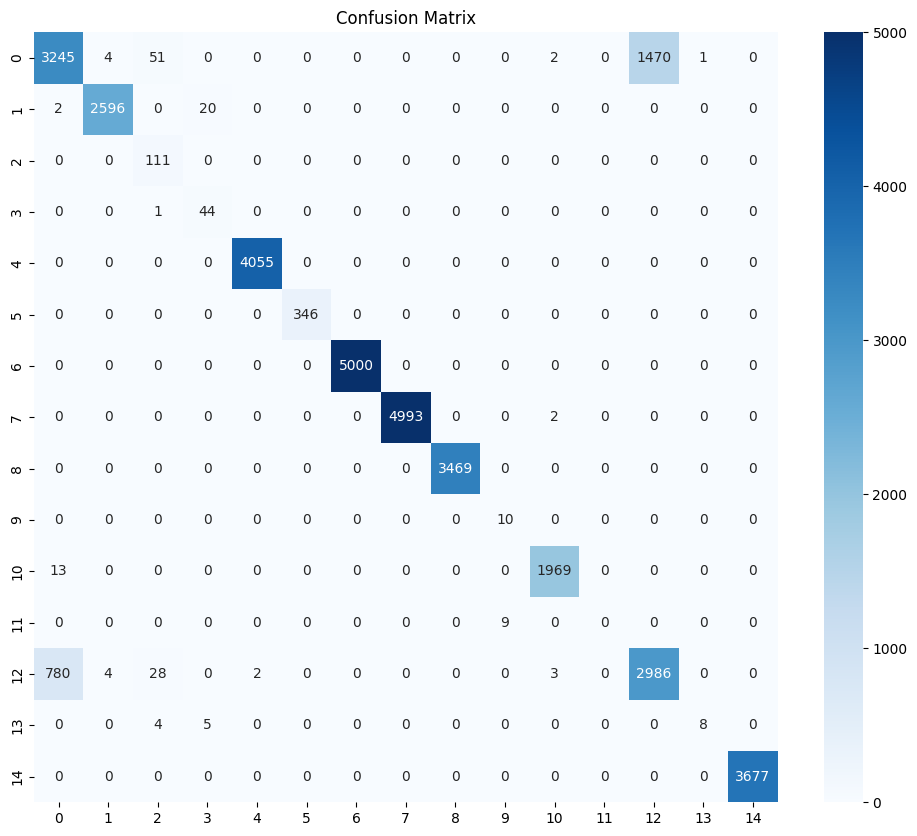

In [ ]:
print("Cell 20: Evaluation Plots...")

plt.figure(figsize=(12, 10))
sns.heatmap(confusion_matrix(y_test, y_pred), annot=True, fmt='d', cmap='Blues')
plt.title('Confusion Matrix')
plt.savefig(OUTPUT_FOLDER + 'figures/confusion_matrix.png', dpi=300)
plt.show()

# **Model Comparison Bar Chart**

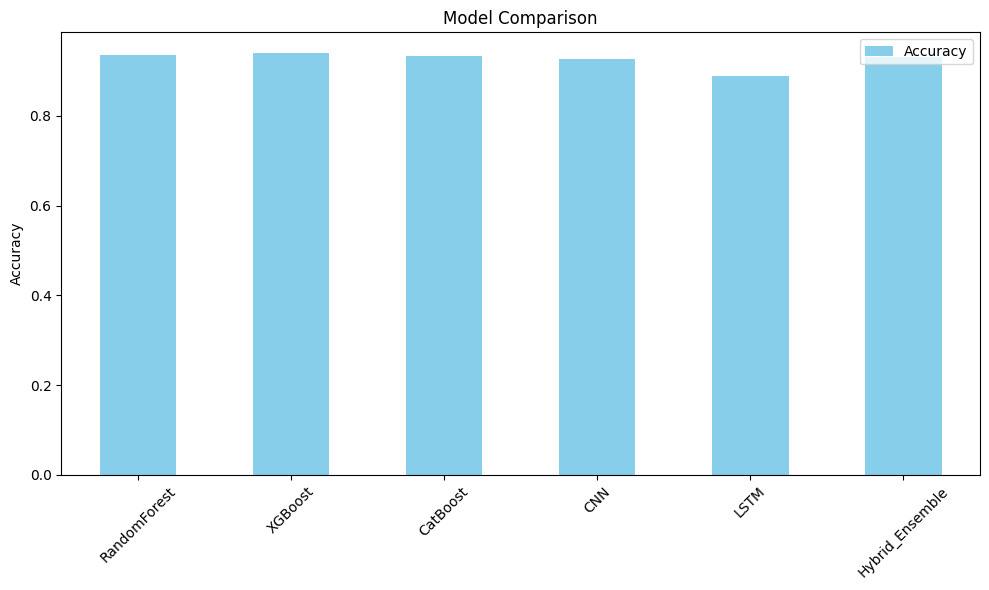

In [ ]:
comparison = pd.DataFrame.from_dict(results, orient='index', columns=['Accuracy'])
comparison.plot(kind='bar', figsize=(10, 6), color='skyblue')
plt.title('Model Comparison')
plt.ylabel('Accuracy')
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig(OUTPUT_FOLDER + 'figures/model_comparison.png', dpi=300)
plt.show()

Cell 21: Plotting ROC Curves...
1091/1091 ━━━━━━━━━━━━━━━━━━━━ 14s 13ms/step
1091/1091 ━━━━━━━━━━━━━━━━━━━━ 28s 26ms/step


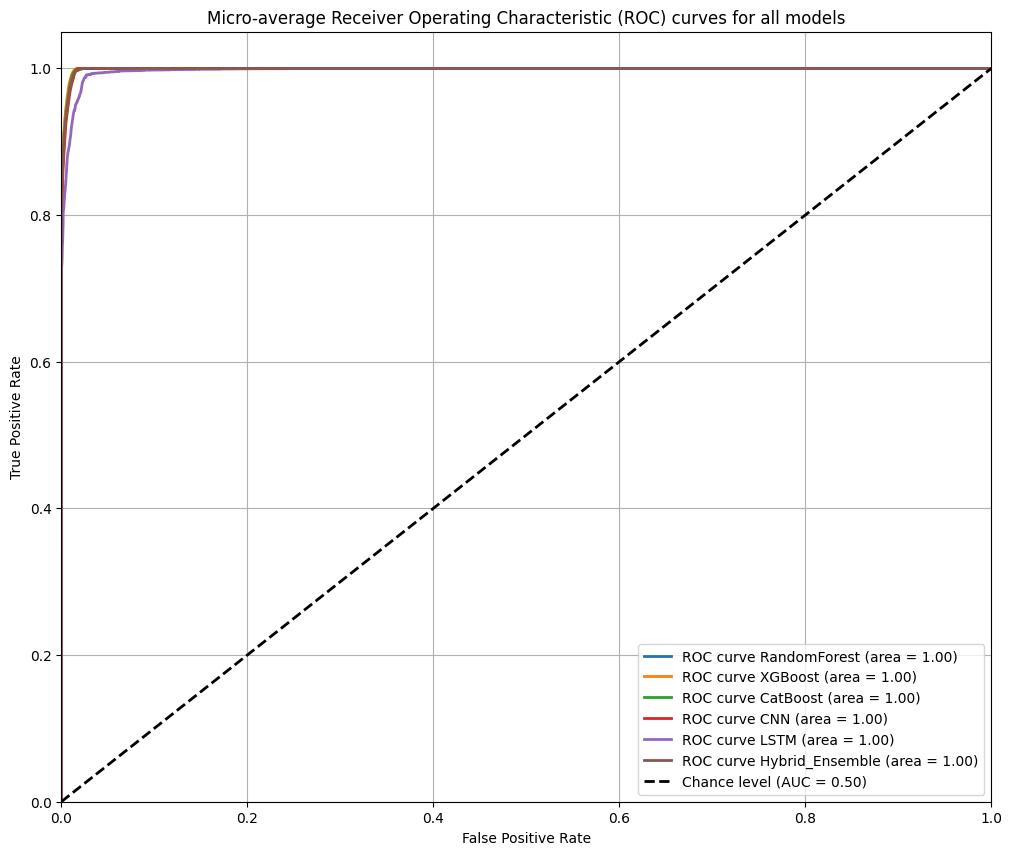

✅ ROC curves plotted and saved!


In [ ]:
from sklearn.metrics import roc_curve, auc
from sklearn.preprocessing import label_binarize
import matplotlib.pyplot as plt
import numpy as np

print("Cell 21: Plotting ROC Curves...")

# Binarize the true labels for multi-class ROC (One-vs-Rest strategy)
n_classes = len(le.classes_)
y_test_binarized = label_binarize(y_test, classes=range(n_classes))

plt.figure(figsize=(12, 10))
lw = 2

model_names_to_plot = ['RandomForest', 'XGBoost', 'CatBoost', 'CNN', 'LSTM', 'Hybrid_Ensemble']
model_predictions = {}

# Get predicted probabilities for each model
# Traditional ML models
for name, model in models.items():
    model_predictions[name] = model.predict_proba(X_test_scaled)

# Deep Learning models (using X_test_dl)
model_predictions['CNN'] = cnn_model.predict(X_test_dl)
model_predictions['LSTM'] = lstm_model.predict(X_test_dl)

# Hybrid Ensemble probabilities are already available
model_predictions['Hybrid_Ensemble'] = hybrid_probs

# Plot Micro-average ROC curve for each model
for name in model_names_to_plot:
    y_score = model_predictions[name]

    # Compute micro-average ROC curve and ROC area
    # ravel() is used to flatten the arrays for roc_curve calculation across all classes
    fpr_micro, tpr_micro, _ = roc_curve(y_test_binarized.ravel(), y_score.ravel())
    roc_auc_micro = auc(fpr_micro, tpr_micro)

    plt.plot(fpr_micro, tpr_micro, lw=lw,
             label=f'ROC curve {name} (area = {roc_auc_micro:0.2f})')

plt.plot([0, 1], [0, 1], 'k--', lw=lw, label='Chance level (AUC = 0.50)')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Micro-average Receiver Operating Characteristic (ROC) curves for all models')
plt.legend(loc="lower right")
plt.grid(True)
plt.savefig(OUTPUT_FOLDER + 'figures/roc_curves_micro_avg.png', dpi=300)
plt.show()

print("✅ ROC curves plotted and saved!")

Plotting Model Accuracy Comparison...


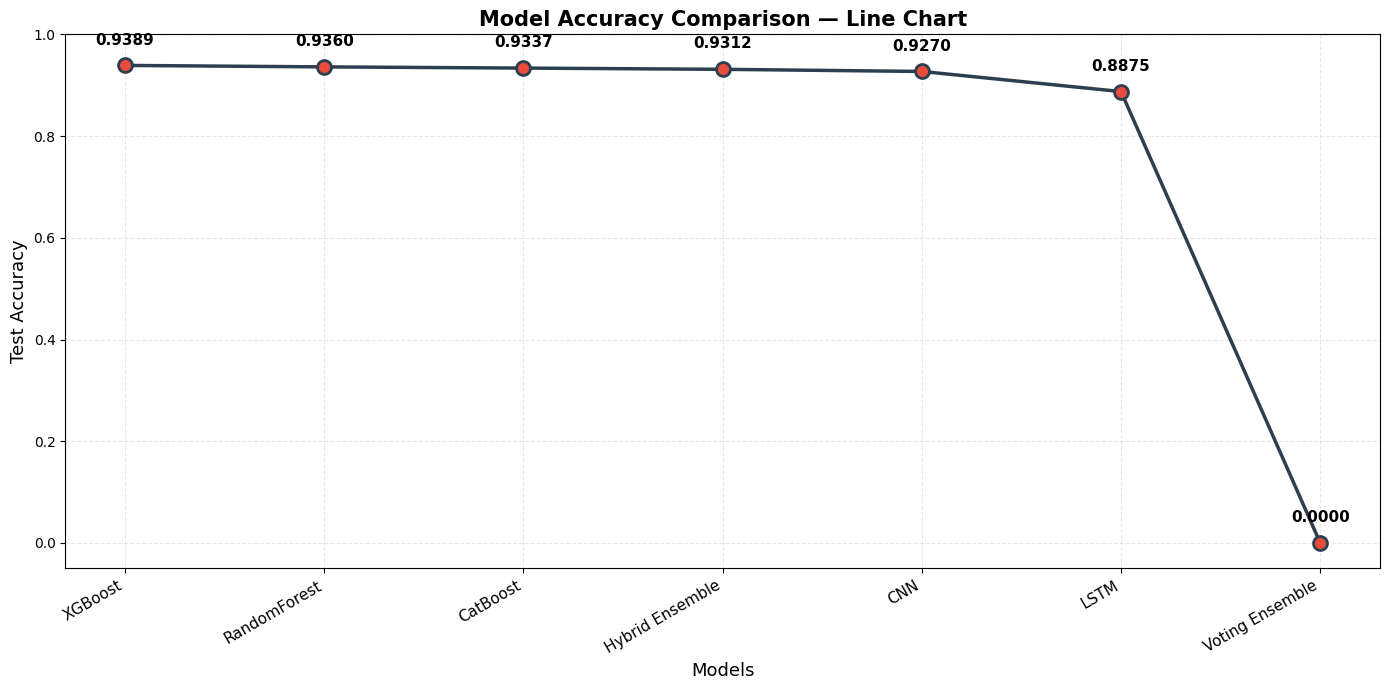

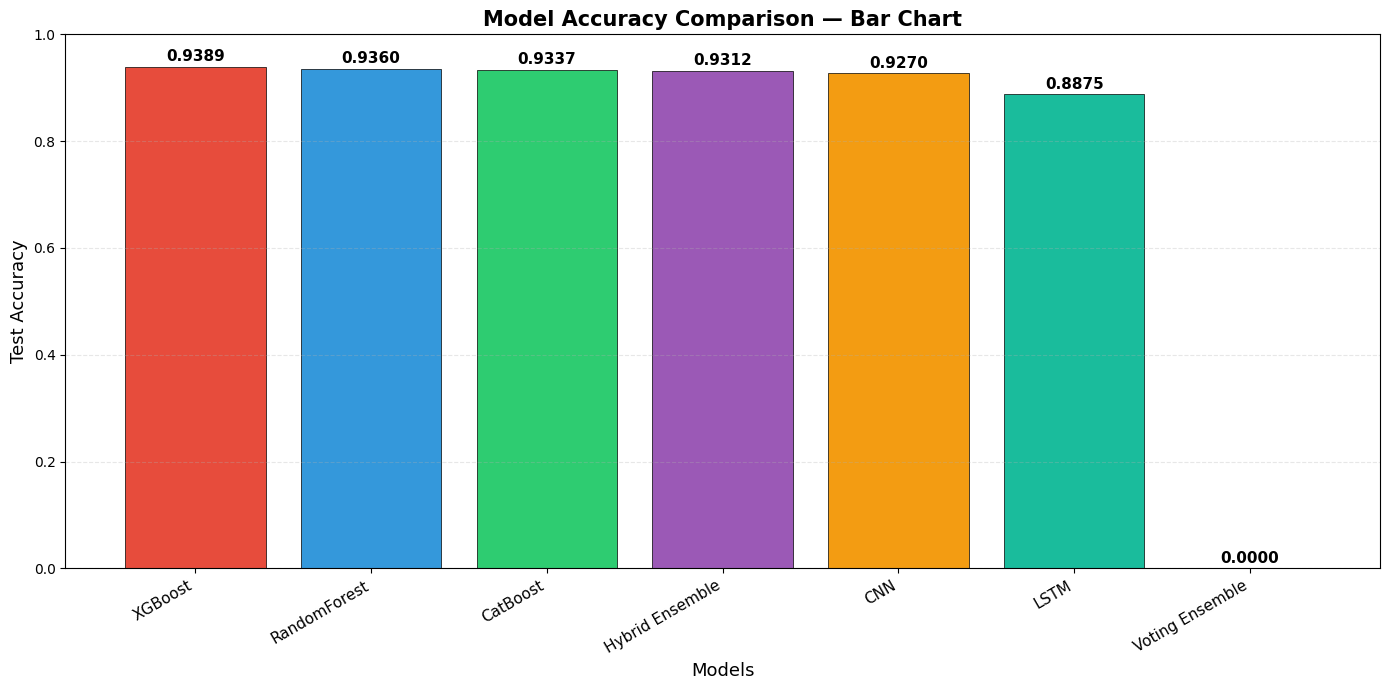

✅ Accuracy comparison charts saved!


In [ ]:
"""# **Model Accuracy Comparison Line Chart**"""

import matplotlib.pyplot as plt

print("Plotting Model Accuracy Comparison...")

# Ensure all results are captured (fallback if any key is missing)
accuracy_data = {
    'RandomForest': results.get('RandomForest', 0),
    'XGBoost': results.get('XGBoost', 0),
    'CatBoost': results.get('CatBoost', 0),
    'Voting Ensemble': results.get('Voting Ensemble', 0),
    'CNN': results.get('CNN', 0),
    'LSTM': results.get('LSTM', 0),
    'Hybrid Ensemble': results.get('Hybrid_Ensemble', 0)
}

# Sort by accuracy for better visual flow
sorted_models = dict(sorted(accuracy_data.items(), key=lambda x: x[1], reverse=True))
model_names = list(sorted_models.keys())
accuracies = list(sorted_models.values())

# --- Line Chart ---
plt.figure(figsize=(14, 7))

plt.plot(model_names, accuracies, marker='o', markersize=10, linewidth=2.5,
         color='#2c3e50', markerfacecolor='#e74c3c', markeredgewidth=2)

# Add value labels on each point
for i, (name, acc) in enumerate(zip(model_names, accuracies)):
    plt.annotate(f'{acc:.4f}', (i, acc), textcoords="offset points",
                 xytext=(0, 15), ha='center', fontsize=11, fontweight='bold')

plt.ylim([min(accuracies) - 0.05, 1.0])
plt.ylabel('Test Accuracy', fontsize=13)
plt.xlabel('Models', fontsize=13)
plt.title('Model Accuracy Comparison — Line Chart', fontsize=15, fontweight='bold')
plt.xticks(rotation=30, ha='right', fontsize=11)
plt.grid(True, alpha=0.3, linestyle='--')
plt.tight_layout()
plt.savefig(OUTPUT_FOLDER + 'figures/accuracy_line_chart.png', dpi=300)
plt.show()

# --- Bar Chart (Side-by-side for report) ---
plt.figure(figsize=(14, 7))
colors = ['#e74c3c', '#3498db', '#2ecc71', '#9b59b6', '#f39c12', '#1abc9c', '#e91e63']
bars = plt.bar(model_names, accuracies, color=colors[:len(model_names)], edgecolor='black', linewidth=0.5)

for bar, acc in zip(bars, accuracies):
    plt.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.005,
             f'{acc:.4f}', ha='center', va='bottom', fontsize=11, fontweight='bold')

plt.ylim([0, 1.0])
plt.ylabel('Test Accuracy', fontsize=13)
plt.xlabel('Models', fontsize=13)
plt.title('Model Accuracy Comparison — Bar Chart', fontsize=15, fontweight='bold')
plt.xticks(rotation=30, ha='right', fontsize=11)
plt.grid(axis='y', alpha=0.3, linestyle='--')
plt.tight_layout()
plt.savefig(OUTPUT_FOLDER + 'figures/accuracy_bar_chart.png', dpi=300)
plt.show()

print("✅ Accuracy comparison charts saved!")

# **Explainability (SHAP)**

Cell 21: SHAP Explainability...


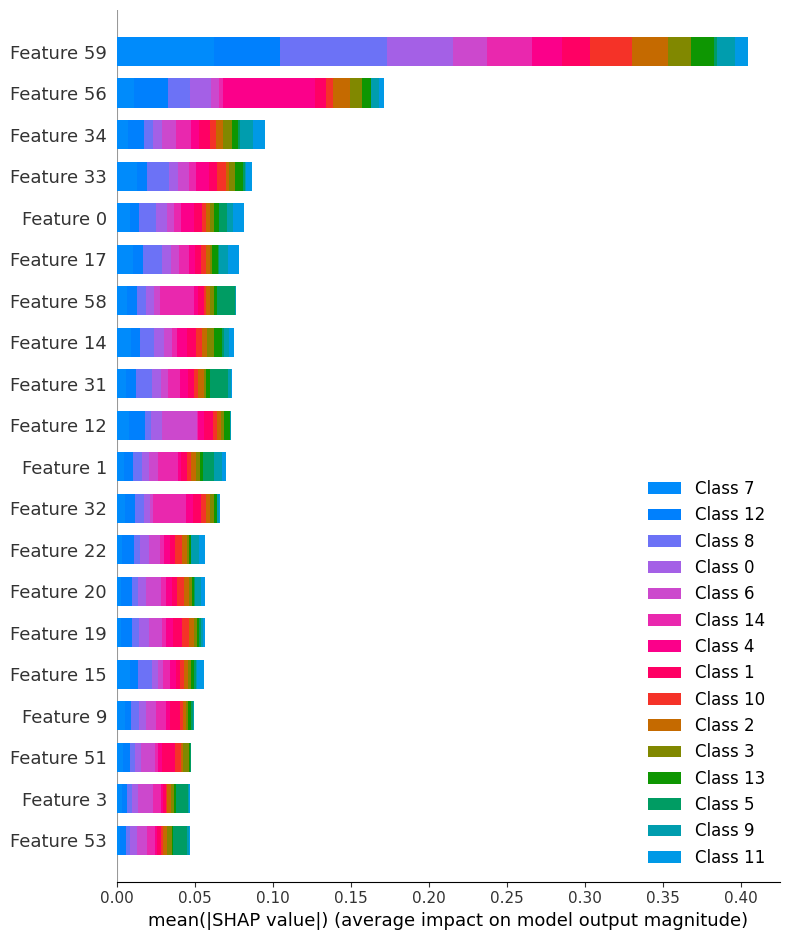

In [ ]:
print("Cell 21: SHAP Explainability...")

import shap
explainer = shap.TreeExplainer(rf)
shap_values = explainer.shap_values(X_test_scaled[:80])
shap.summary_plot(shap_values, X_test_scaled[:80], plot_type="bar")

# **Artifact Saving**

In [ ]:
print("Cell 22: Saving Artifacts...")

# Save ML ensemble
joblib.dump(voting, OUTPUT_FOLDER + 'models/best_voting_ensemble.pkl')
joblib.dump(scaler, OUTPUT_FOLDER + 'models/scaler.pkl')
joblib.dump(le, OUTPUT_FOLDER + 'models/label_encoder.pkl')
joblib.dump(feature_importance, OUTPUT_FOLDER + 'models/feature_importance.pkl')

# Save DL models
cnn_model.save(OUTPUT_FOLDER + 'models/cnn_model_final.keras')
lstm_model.save(OUTPUT_FOLDER + 'models/lstm_model_final.keras')

# Save training histories
joblib.dump(cnn_history.history, OUTPUT_FOLDER + 'models/cnn_history.pkl')
joblib.dump(lstm_history.history, OUTPUT_FOLDER + 'models/lstm_history.pkl')

print("✅ All models saved successfully!")
print(f"Location: {OUTPUT_FOLDER}models/")
print("\n🎉 Full Project Completed!")

Cell 22: Saving Artifacts...
✅ All models saved successfully!
Location: /content/drive/MyDrive/IDS_Model_Final_2/models/

🎉 Full Project Completed!
